### Into the Gravity Well

In [16]:
# import necessary packages
import numpy as np
from scipy.integrate import solve_ivp
from scipy.integrate import quad
from scipy.optimize import brentq
import matplotlib.pyplot as plt 
import matplotlib as mpl

# set geometrized units
G = c = 1
M = 1

# 1. Define equations we want to integrate

Define function photon_ODE(phi, y):

    u = y[0]  # inverse radius (1/r)
    v = y[1]  # du/dphi

    du/dphi = v
    dv/dphi = 3*M*u^2 - u

    Return both derivatives

In [39]:
def photon_ODE(phi, y, M):
    u = y[0]  # inverse radius (1/r)
    v = y[1]  # du/dphi

    du = v # du/dphi
    dv = 3*M*u**2 - u #dv/dphi

    return du, dv


# 2. Set up initial conditions

For a chosen value of b:

    Set u0 = 1/r0

    Calculate initial du/dphi using:
        v0 = sqrt(1/b^2 - u0^2 + 2*M*u0^3)

    # as phi increases, u increases (r decreases)

    Initial conditions = [u0, v0]

In [40]:
r0 = 100.0                      # starting radius
u0 = 1/r0
b_values = np.linspace(2, 10, 20)   # b_crit = 3*sqrt(3)*M ≈ 5.196M
v_values = np.sqrt(1/b_values**2 - u0**2 + 2*M*u0**3)

# 3. Integrate photon trajectory

Use scipy.integrate.solve_ivp:

    Input:
        photon_ODE
        initial conditions
        range of phi
        integration tolerances

    Stop integration when:
        - photon reaches event horizon (r = 2M)
        OR
        - photon returns to r0 while moving outward

    If neither happens before maximum phi:
        trajectory is unresolved

    Store phi and u values

    Convert back to r = 1/u

    Convert to Cartesian coordinates:
        x = r*cos(phi)
        y = r*sin(phi)

    Plot trajectory

In [ ]:
# possible photon outcomes

# case when photon hits horizon
def hit_horizon(phi, y, M):
    return y[0] - 1/(2*M) # negative when photon is outside horizon, zero at horizon, positive inside
hit_horizon.terminal = True # stop integration when event fires
hit_horizon.direction = 1   # only count crossing when function goes from negative to positive

# case when photon comes back to starting radius
def make_returned(u0):
    def returned(phi, y, M): # becomes positve as photon falls inward
        return y[0] - u0
    returned.terminal = True    
    returned.direction = -1     # only count when value goes from positive to negative, ie photon moving outward

returned = make_returned(u0) # need this for classift and trace to call make_returned

results = []

# trace one photon per impact parameter, classify outcome, and store version for plotting
for b, v0 in zip(b_values, v_values):
    # integrate orbit equation - ODE, phi range, initial conditions, arguments, stopping conditions, accuracy, keep interpolating function 
    sol = solve_ivp(photon_ODE, [0, 20*np.pi], [u0, v0], args=(M,),
                    events=[hit_horizon, returned],
                    rtol=1e-10, atol=1e-12, dense_output=True)

    # classify
    if len(sol.t_events[0]) > 0:
        outcome = "captured"
    elif len(sol.t_events[1]) > 0:
        outcome = "escaped"
    else:
        outcome = "unresolved"   # φ range too short, likely b ≈ b_crit


    # uniform grid via dense output, smoother for plotting
    phi_grid = np.linspace(0, sol.t[-1], 1000)
    u_grid = sol.sol(phi_grid)[0]

    results.append({
        "b": b,
        "outcome": outcome,
        "phi": phi_grid,
        "u": u_grid,
        "phi_end": sol.t[-1],
    })

    

# 4. Repeat for diff values of b

For each b in chosen list:

    Solve photon trajectory

    If photon reaches horizon:
        classify as CAPTURED

    Else if photon returns to large radius:
        classify as ESCAPED

    Store result

Plot trajectories together
Draw event horizon (r = 2M)
Draw photon sphere (r = 3M)

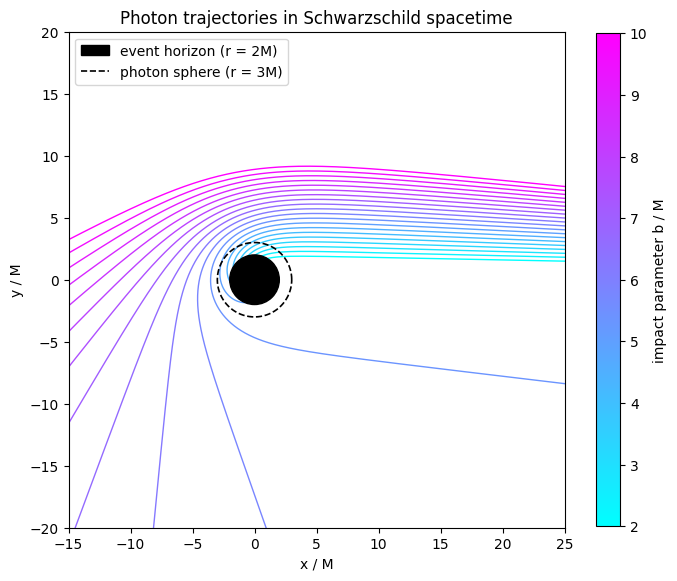

In [46]:
# plot trajectories
fig, ax = plt.subplots(figsize=(8, 8))

colors = {"captured": "tab:red", "escaped": "tab:blue", "unresolved": "tab:orange"}
plotted = set()

# colormap for b values 
norm = mpl.colors.Normalize(vmin=b_values.min(), vmax=b_values.max())
cmap = plt.cm.cool

# draw the rays
for res in results:
    # convert to cartesian coordinates
    r = 1/res["u"]
    x = r*np.cos(res["phi"])
    y = r*np.sin(res["phi"])

    # label each outcome 
    label = res["outcome"] if res["outcome"] not in plotted else None
    plotted.add(res["outcome"])
    ax.plot(x, y, color=cmap(norm(res["b"])), lw=1)


# event horizon (r = 2M)
ax.add_patch(plt.Circle((0, 0), 2*M, color="k", zorder=3, label="event horizon (r = 2M)"))

# photon sphere (r = 3M)
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(3*M*np.cos(theta), 3*M*np.sin(theta), "k--", lw=1.2, zorder=4,
        label="photon sphere (r = 3M)")

# b colorbar
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="impact parameter b / M", shrink=0.8)

ax.set_xlim(-15*M, 25*M)
ax.set_ylim(-20*M, 20*M)
ax.set_aspect("equal")
ax.set_xlabel("x / M")
ax.set_ylabel("y / M")
ax.set_title("Photon trajectories in Schwarzschild spacetime")
ax.legend(loc="upper left")
plt.show()

# 5. Numerically determine critical impact parameter
# want to know if our numerical method reproduces the right boundary between photon capture and escape

Choose two b values:
    one where photon is captured
    one where photon escapes

Use bisection:

    b_mid = (b_low + b_high)/2

    Integrate photon trajectory for b_mid

    If captured:
        b_low = b_mid

    If escaped:
        b_high = b_mid

    Repeat until good precision is reached

Calculate numerical b_crit

Compare with:
    b_crit_analytic = 3*sqrt(3)*M

Calculate relative error

In [ ]:
# build initial conditions for photon starting at r0 with impact parameter 
def classify(b, rtol, atol, M=1.0, r0=100.0, phi_max=200*np.pi):
    u0 = 1/r0
    v0 = np.sqrt(1/b**2 - u0**2 + 2*M*u0**3)

    # integrates with two terminal events, phi max set to 200pi because rays near b_crit wind around sphere many times before resolving
    sol = solve_ivp(photon_ODE, [0, phi_max], [u0, v0], args=(M,),
                    events=[hit_horizon, make_returned(u0)],
                    rtol=rtol, atol=atol)
    if len(sol.t_events[0]) > 0: return "captured"
    if len(sol.t_events[1]) > 0: return "escaped"
    return "unresolved"

# bisection
b_crit_analytic = 3*np.sqrt(3)*M
rtol, atol = 1e-12, 1e-14 # relative and absolute error tolerances solve_ivp uses to decide step size. rtol sets correct sig digits, atol sets smallest error possible so steos don't get too small
assert classify(b_low, rtol, atol) == "captured"
assert classify(b_high, rtol, atol) == "escaped"

tol = 1e-10
history = []
while b_high - b_low > tol:
    b_mid = 0.5*(b_low + b_high)
    outcome = classify(b_mid, rtol, atol)
    history.append((b_mid, outcome))

    if outcome == "captured":
        b_low = b_mid
    elif outcome == "escaped":
        b_high = b_mid
    else:
        break   # unresolved: too close to b_crit for this phi_max

b_crit_numeric = 0.5*(b_low + b_high)
rel_error = abs(b_crit_numeric - b_crit_analytic)/b_crit_analytic

print(f"numerical b_crit = {b_crit_numeric:.10f}")
print(f"analytic  b_crit = {b_crit_analytic:.10f}")
print(f"relative error   = {rel_error:.2e}")
print(f"iterations = {len(history)}")

numerical b_crit = 5.1961524227
analytic  b_crit = 5.1961524227
relative error   = 2.84e-13
iterations = 35


# 6. Compare with analytical results
# want to know if our calculated trajectories agree with what GR predicts analytically

For escaping photons:

    Find minimum radius reached (r_min)

    Check Luminet's closest approach relation:
        b^2 = r_min^3 / (r_min - 2*M)

    Calculate deflection angle from trajectory
        # compare incoming/outgoing directions
        # account for finite starting radius

    For large b:
        Compare numerical deflection with 4*M/b

Plot:
    deflection angle vs b
    numerical vs analytical predictions

In [26]:
# trace one ray and extract r_min and the deflection

def turning(phi, y, M): # closest approach
    return y[1]
turning.direction = -1          # v goes from + to -

def trace(b, rtol, atol, M=1.0, r0=100.0, phi_max=200*np.pi):
    u0 = 1/r0
    v0 = np.sqrt(1/b**2 - u0**2 + 2*M*u0**3)
    sol = solve_ivp(photon_ODE, [0, phi_max], [u0, v0], args=(M,),
                    events=[hit_horizon, make_returned(u0), turning],
                    rtol=rtol, atol=atol)
    phi_end = sol.t_events[1][0]
    r_min = 1/sol.y_events[2][0][0]
    return phi_end, r_min


# analytic reference: deflection integral
def f(u, b, M=1.0):
    return 1/b**2 - u**2 + 2*M*u**3

def phi_swept(b, u_start, M=1.0): #Angle swept going from u_start up to u_max and back (exact, finite u_start allowed)
    # roots of 2M u^3 - u^2 + 1/b^2 = 0: one negative, two positive
    roots = np.sort(np.roots([2*M, -1.0, 0.0, 1/b**2]).real)
    u_neg, u_max, u_b = roots          # u_max = turning point, u_b > 1/(3M)

    # polish the turning point to full double precision
    u_max = brentq(f, u_start, 1/(3*M), args=(b, M), xtol=1e-15, rtol=1e-15)

    # integrand 2t / sqrt(f(u_max - t^2)) with the t^2 factored out analytically
    g = lambda t: 2.0/np.sqrt(2*M*(u_max - t**2 - u_neg)*(u_b - u_max + t**2))
    I, _ = quad(g, 0, np.sqrt(u_max - u_start), epsabs=1e-13, epsrel=1e-13)
    return 2*I

def alpha_exact(b, M=1.0):
    return phi_swept(b, 0.0, M) - np.pi          # start/end at infinity

In [24]:
# run and compare
b_scan = b_crit + np.geomspace(0.01, 30, 60) # dense near b_crit, out to weak field

rays = [r for b in b_scan if (r := trace(b, M, r0)) is not None]
b       = np.array([r["b"] for r in rays])
r_min   = np.array([r["r_min"] for r in rays])
alpha_n = np.array([r["alpha"] for r in rays])

# Luminet closest-approach relation
b_from_rmin = np.sqrt(r_min**3/(r_min - 2*M))
print("max rel. error in b^2 = r_min^3/(r_min-2M):", np.max(np.abs(b_from_rmin - b)/b))

# Deflection references
alpha_ex  = np.array([alpha_exact(bi, M) for bi in b])
alpha_w1  = 4*M/b
alpha_w2  = 4*M/b + (15*np.pi/4)*(M/b)**2

# Exact swept angle at the same finite r0, to isolate the r0 effect
phi_ex_r0 = np.array([phi_swept(bi, 1/r0, M) for bi in b])
print("max |phi_end numeric - exact (same r0)|:",
      np.max(np.abs(np.array([r["phi_end"] for r in rays]) - phi_ex_r0)))

max rel. error in b^2 = r_min^3/(r_min-2M): 8.297062562172678e-13
max |phi_end numeric - exact (same r0)|: 4.132871822548623e-11


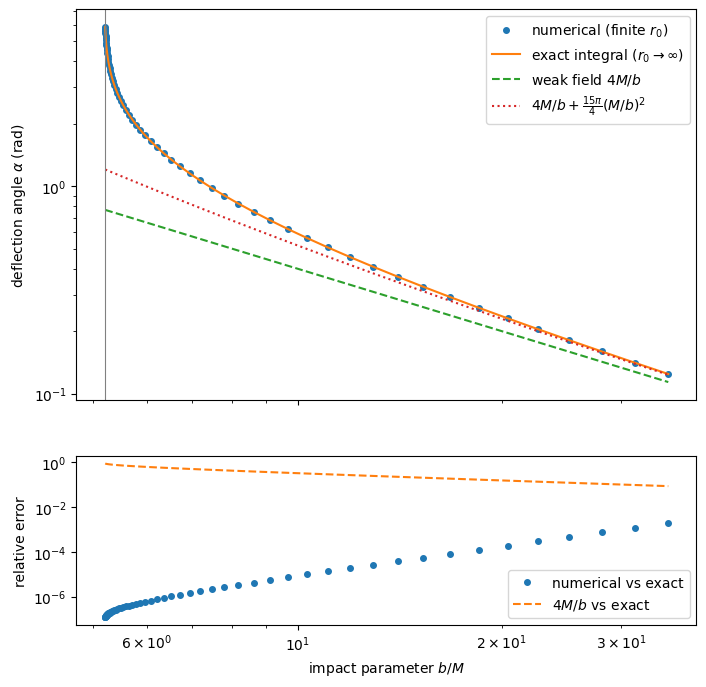

In [25]:
# plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                               gridspec_kw=dict(height_ratios=[3, 1.3]))

ax1.loglog(b, alpha_n, "o", ms=4, label="numerical (finite $r_0$)")
ax1.loglog(b, alpha_ex, "-", label="exact integral ($r_0\\to\\infty$)")
ax1.loglog(b, alpha_w1, "--", label=r"weak field $4M/b$")
ax1.loglog(b, alpha_w2, ":", label=r"$4M/b + \frac{15\pi}{4}(M/b)^2$")
ax1.axvline(b_crit, color="gray", lw=0.8)
ax1.set_ylabel("deflection angle $\\alpha$ (rad)")
ax1.legend()

ax2.loglog(b, np.abs(alpha_n - alpha_ex)/alpha_ex, "o", ms=4, label="numerical vs exact")
ax2.loglog(b, np.abs(alpha_w1 - alpha_ex)/alpha_ex, "--", label="$4M/b$ vs exact")
ax2.set_xlabel("impact parameter $b/M$")
ax2.set_ylabel("relative error")
ax2.legend()
plt.show()

# 7. Numerical accuracy/convergence

Repeat calculations using different solve_ivp tolerances

Compare:
    calculated deflection angles
    minimum radius
    numerical b_crit

Calculate differences/errors
Plot error vs solver tolerance

Possibly implement our own RK4 and compare with adaptive solve_ivp

In [37]:
# define bisection as function of tolerance
b_crit = 3*np.sqrt(3)*M
def bisect_bcrit(rtol, atol, b_low=4.0, b_high=7.0, tol=1e-13, max_iter=60):
    for _ in range(max_iter):
        if b_high - b_low < tol: break
        b_mid = 0.5*(b_low + b_high)
        out = classify(b_mid, rtol, atol)
        if out == "captured":   b_low = b_mid
        elif out == "escaped":  b_high = b_mid
        else: break
    return 0.5*(b_low + b_high)

# conduct tolerance sweep
b_test = b_crit + np.array([0.05, 0.5, 3.0, 10.0])

# solver-independent references
phi_ref  = np.array([phi_swept(b, 1/r0, M) for b in b_test])
rmin_ref = np.array([1/brentq(f, 0, 1/(3*M), args=(b, M), xtol=1e-15, rtol=1e-15)
                     for b in b_test])

rtols = 10.0**np.arange(-4, -14, -1)      # 1e-4 ... 1e-13
err_alpha, err_rmin, err_bcrit = [], [], []

for rtol in rtols:
    atol = 1e-2*rtol                       # keep atol tied to rtol
    phi_n, rmin_n = np.array([trace(b, rtol, atol, M, r0) for b in b_test]).T

    err_alpha.append(np.max(np.abs(phi_n - phi_ref)))          # alpha error = phi_end error
    err_rmin.append(np.max(np.abs(rmin_n - rmin_ref)/rmin_ref))
    err_bcrit.append(abs(bisect_bcrit(rtol, atol) - b_crit)/b_crit)
    print(f"rtol={rtol:.0e}  d_alpha={err_alpha[-1]:.2e}  "
          f"d_rmin={err_rmin[-1]:.2e}  d_bcrit={err_bcrit[-1]:.2e}")

rtol=1e-04  d_alpha=3.73e-03  d_rmin=1.61e-04  d_bcrit=3.49e-05
rtol=1e-05  d_alpha=2.97e-04  d_rmin=1.31e-05  d_bcrit=2.78e-06
rtol=1e-06  d_alpha=2.39e-05  d_rmin=1.07e-06  d_bcrit=2.21e-07
rtol=1e-07  d_alpha=1.87e-06  d_rmin=8.44e-08  d_bcrit=1.71e-08
rtol=1e-08  d_alpha=1.48e-07  d_rmin=6.69e-09  d_bcrit=1.33e-09
rtol=1e-09  d_alpha=1.22e-08  d_rmin=7.12e-10  d_bcrit=1.08e-10
rtol=1e-10  d_alpha=1.06e-09  d_rmin=7.51e-11  d_bcrit=9.19e-12
rtol=1e-11  d_alpha=9.61e-11  d_rmin=7.87e-12  d_bcrit=8.23e-13
rtol=1e-12  d_alpha=9.03e-12  d_rmin=8.14e-13  d_bcrit=6.84e-14
rtol=1e-13  d_alpha=9.64e-13  d_rmin=8.30e-14  d_bcrit=2.73e-15


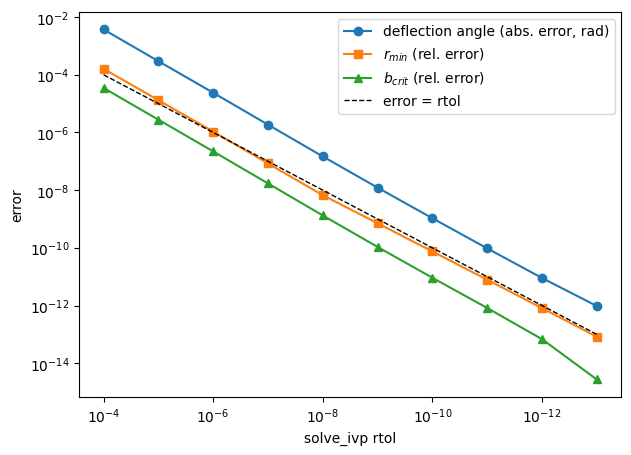

In [38]:
# plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(rtols, err_alpha, "o-", label=r"deflection angle (abs. error, rad)")
ax.loglog(rtols, err_rmin,  "s-", label=r"$r_{min}$ (rel. error)")
ax.loglog(rtols, err_bcrit, "^-", label=r"$b_{crit}$ (rel. error)")
ax.loglog(rtols, rtols, "k--", lw=1, label="error = rtol")
ax.set_xlabel("solve_ivp rtol")
ax.set_ylabel("error")
ax.invert_xaxis()
ax.legend()
plt.show()


# 8. Black hole imaging (if we have time)

Create grid of photon impact parameters

For each ray:
    Integrate trajectory
    Determine whether captured or escaped

Captured rays = black hole shadow
Escaping rays = surrounding region

Plot resulting shadow